# SECOM — Imputation, Boruta Feature Selection, Balancing, Scaling & Pipeline (Weeks 3–5)

**CRISP-DM phases covered:** Data Preparation (Weeks 3–5) → Initial Modeling & Leakage-Free Validation.  
Continues directly from Notebook 01 (`data/processed/train_reduced.csv` & `train_prepared.csv`: `1,253` training wafers, `83` defective = `6.62%`, `450` reduced features).

| Section | Content | Manual / Task |
| :--- | :--- | :--- |
| **1** | Duplicate features check on `X_train` | §4.3 / Week 3 |
| **2** | Missing values after `3σ` capping & Scaled `k-NN` (`k=5`) imputation | §6 / T12 (Week 3) |
| **3** | First baseline model: default Random Forest (Training vs. 5-Fold CV) | T13 (Week 3) |
| **4** | Feature Selection with **Boruta** (`perc=100` vs. **`perc=99` locked (`25` features)** vs. `perc=98`) | §7 / T15 (Week 4) |
| **5** | Class Imbalance & Balancers (`SMOTE`, `ROSE-style`, `ADASYN`, `Class weights`) | §9 / T16 (Week 4) |
| **6** | Initial Confusion Matrix, Type I/II Costs (`100` / `400`), ROC & PR Curves | §13 / T17 (Week 4) |
| **7** | Normality Audit & Visual Proof (`No transform` vs. `Yeo-Johnson` on RF & LogReg) | §8.1–8.2 (Week 5) |
| **8** | Min-Max Scaling (`[0, 1]`), Leakage-Free `imblearn` Pipeline & Process Map | §8.3–8.5, §10 (Week 5) |
| **9** | Training Error vs. Validation Error & Model Complexity (`max_depth` sweep) | Week 5 |
| **10** | Summary, Pipeline State & Next Steps (Week 6 Grid Search & Cost Thresholding) | — |

> **Zero-Leakage Rule:** `data/processed/test_holdout.csv` (`314` wafers, `21` defective) is verified by its SHA-256 checksum and **never read** in any cell of this notebook. All statistics, imputers, Boruta selections, scalers, and SMOTE resamplers are fitted strictly on `X_train`.

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from secom_analysis.week2.preparation import load_split, sip_table, verify_sealed
from secom_analysis.week3.impute import RANDOM_STATE, duplicate_features, first_model, knn_imputer
from secom_analysis.week4.feature_selection import ensure_prepared_training_split
from secom_analysis.week4.balancing_and_eval import COST_FN, COST_FP
from secom_analysis.week5.pipeline_and_error import run_pipeline_checks

warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
PROCESSED = ROOT / "data" / "processed"
W4_REPORTS = ROOT / "reports" / "week4"
W5_REPORTS = ROOT / "reports" / "week5"

# Load Week 2 outputs (automatically builds them from UCI if missing)
X_train_capped, y_train = ensure_prepared_training_split(ROOT / "data" / "raw", PROCESSED)
X_train_reduced, y_red = load_split(PROCESSED / "train_reduced.csv")
selected_meta = json.loads((PROCESSED / "selected_features.json").read_text(encoding="utf-8"))
SELECTED = selected_meta["selected_features"]

assert verify_sealed(PROCESSED / "test_holdout.csv"), "Test set checksum mismatch!"
assert (X_train_capped.index == X_train_reduced.index).all() and (y_train == y_red).all()

print(f"Training split : {X_train_capped.shape[0]:,} wafers × {X_train_capped.shape[1]} features")
print(f"Defect rate    : {int(y_train.sum())} defective ({y_train.mean():.2%}) | {int((y_train == 0).sum()):,} pass")
print(f"Boruta set     : {len(SELECTED)} features (perc={selected_meta.get('perc', 99)})")
print("Test hold-out  : SEALED (SHA-256 verified, not read)")

Training split : 1,253 wafers × 450 features
Defect rate    : 83 defective (6.62%) | 1,170 pass
Boruta set     : 25 features (perc=99)
Test hold-out  : SEALED (SHA-256 verified, not read)


## 1. Duplicate Feature Check on `X_train` (Manual §4.3 / Week 3)

Before imputation, we verify whether any two columns in the `450` kept training sensors are exact copies of each other (including matching `NaN` positions).

In [2]:
dupes = duplicate_features(X_train_capped)
print(f"Exact duplicate columns among the {X_train_capped.shape[1]} kept training features: {len(dupes)}")
display(sip_table([
    {
        "options": "Check exact duplicate columns on X_train (450 kept features)",
        "pros_cons": "+ Prevents redundant identical sensors from distorting k-NN distances and tree splits",
        "decision": "Verified (0 duplicates found)",
        "consequence": "450 -> 450 features (all 104 raw duplicates were already dropped as zero-variance in Week 2)",
    }
]))

Exact duplicate columns among the 450 kept training features: 0


Options / approaches,Pro and con,Decision made,Consequence
nan,nan,nan,nan


## 2. Missing Values After `3σ` Capping & Scaled `k-NN` Imputation (Manual §6 / T12)

Because Week 2 used **`3σ` capping** (rather than removing outliers to `NaN`), no additional gaps were injected.  
- **Why mean imputation is rejected:** Replacing missing sensor blocks with a single column mean collapses feature variance, distorts distributions, and ignores correlations across sub-tool sensors (explicitly prohibited by the course manual).
- **Chosen imputer:** Distance-weighted **`k-NN` (`k = 5`)** wrapped inside `ScaledImputer` (standardises features internally before computing Euclidean neighbour distances, then maps filled values back to original sensor units and clips to the observed training range).

In [3]:
nan_before = int(X_train_capped.isna().sum().sum())
imputer = knn_imputer(n_neighbors=5)
X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train_capped),
    index=X_train_capped.index,
    columns=X_train_capped.columns,
)
nan_after = int(X_train_imputed.isna().sum().sum())

print(f"Missing cells before k-NN (k=5) imputation : {nan_before:,}")
print(f"Missing cells after  k-NN (k=5) imputation : {nan_after:,}")

display(sip_table([
    {
        "options": "Mean imputation",
        "pros_cons": "+ Fast / - Collapses variance, distorts skewed sensors; prohibited by manual",
        "decision": "Rejected",
        "consequence": "Not used",
    },
    {
        "options": "Median / MICE (BayesianRidge, ExtraTrees)",
        "pros_cons": "+ Robust or model-based / - Median spikes at one value; MICE is 20-140x slower with <0.006 PR-AUC gap",
        "decision": "Documented alternatives",
        "consequence": "Benchmarked in scientific diary (D-025/D-029)",
    },
    {
        "options": "Scaled k-NN imputation (k = 5, distance-weighted)",
        "pros_cons": "+ Preserves local multivariate sensor structure; course manual's required starting point; k adjustable in Week 6 / - Requires internal scaling",
        "decision": "Chosen",
        "consequence": f"{nan_before:,} NaNs -> {nan_after} NaNs on X_train (1,253 × 450)",
    },
]))

Missing cells before k-NN (k=5) imputation : 11,211
Missing cells after  k-NN (k=5) imputation : 0


Options / approaches,Pro and con,Decision made,Consequence
nan,nan,nan,nan
nan,nan,nan,nan
nan,nan,nan,nan


## 3. First Baseline Model: Default Random Forest (Week 3 / T13)

To illustrate why **training-set accuracy is misleading**, we fit a default `500`-tree Random Forest on `X_train` and compare its performance on the **seen training rows** against **unseen Stratified 5-Fold CV** (with `k-NN` refitted inside each fold).

In [4]:
baseline_rf = first_model(X_train_capped, y_train, n_neighbors=5)
display(baseline_rf)

,evaluated_on,accuracy,recall,TP,FN,FP,TN,pr_auc,roc_auc
0,training rows (seen),1.000000,1.0,83,0,0,1170,NaN,NaN
1,5-fold CV (unseen),0.933759,0.0,0,83,0,1170,0.145951,0.704685


**Key Observation:** On the training rows it already memorised, the Random Forest reports **`100.0%` accuracy and `100.0%` recall**. Under unseen 5-fold CV, accuracy matches the trivial always-pass baseline (`93.38%`), while **defect recall collapses to `0.0%` (`0 / 83` defects caught)**. This directly motivates **Week 4: Boruta feature selection + class balancing**.

---

## 4. Sophisticated Feature Selection with Boruta (Manual §7 / T15 — Week 4)

### Feature Reduction vs. Feature Selection
- **Rough Feature Reduction (Week 2):** *Unsupervised* data hygiene (`590 → 450`: dropped `116` zero-variance and `24` `>60%` missing sensors without looking at target $y$).
- **Feature Selection (Week 4):** *Supervised* signal discovery using target $y$ on `X_train` (Filter: ANOVA F-test; Embedded: RF impurity; Wrapper: **Boruta**).

### How Boruta Works & Why We Locked `perc = 99`
At each iteration, Boruta duplicates all `450` sensors and randomly shuffles each copy to create **shadow features** (pure noise benchmarks). A balanced shallow Random Forest (`max_depth=5`) scores all `900` columns; real features that beat the shadow threshold earn a "hit", and a binomial test separates **Confirmed**, **Tentative** (kept per manual), and **Rejected** features.

Because `450` random shadow draws against only `83` defective wafers occasionally produce 1–2 extreme noise spikes, we compared **`perc = 100`** (strict max shadow), **`perc = 99`** (99th percentile), and **`perc = 98`** (98th percentile), locking in **`perc = 99` (`25` features: `22` confirmed + `3` tentative)**.

,option,perc,confirmed,tentative,n_features,roc_auc_mean,roc_auc_sd,pr_auc_mean,pr_auc_sd,decision
0,All features,NaN,0,0,450,0.6995,0.0676,0.2051,0.0675,Baseline only
1,Boruta (perc=100),100.0,12,4,16,0.7301,0.0728,0.2251,0.0640,Tested alternative
2,Boruta (perc=99),99.0,22,3,25,0.7904,0.0587,0.2584,0.0592,Chosen (locked in)
3,Boruta (perc=98),98.0,29,5,34,0.8059,0.0376,0.2658,0.0310,Tested alternative


Confirmed (22): ['feature_021', 'feature_031', 'feature_033', 'feature_059', 'feature_064', 'feature_065', 'feature_081', 'feature_103', 'feature_125', 'feature_129', 'feature_130', 'feature_205', 'feature_213', 'feature_281', 'feature_319', 'feature_341', 'feature_351', 'feature_477', 'feature_488', 'feature_510', 'feature_519', 'feature_577']
Tentative (3): ['feature_183', 'feature_280', 'feature_455']


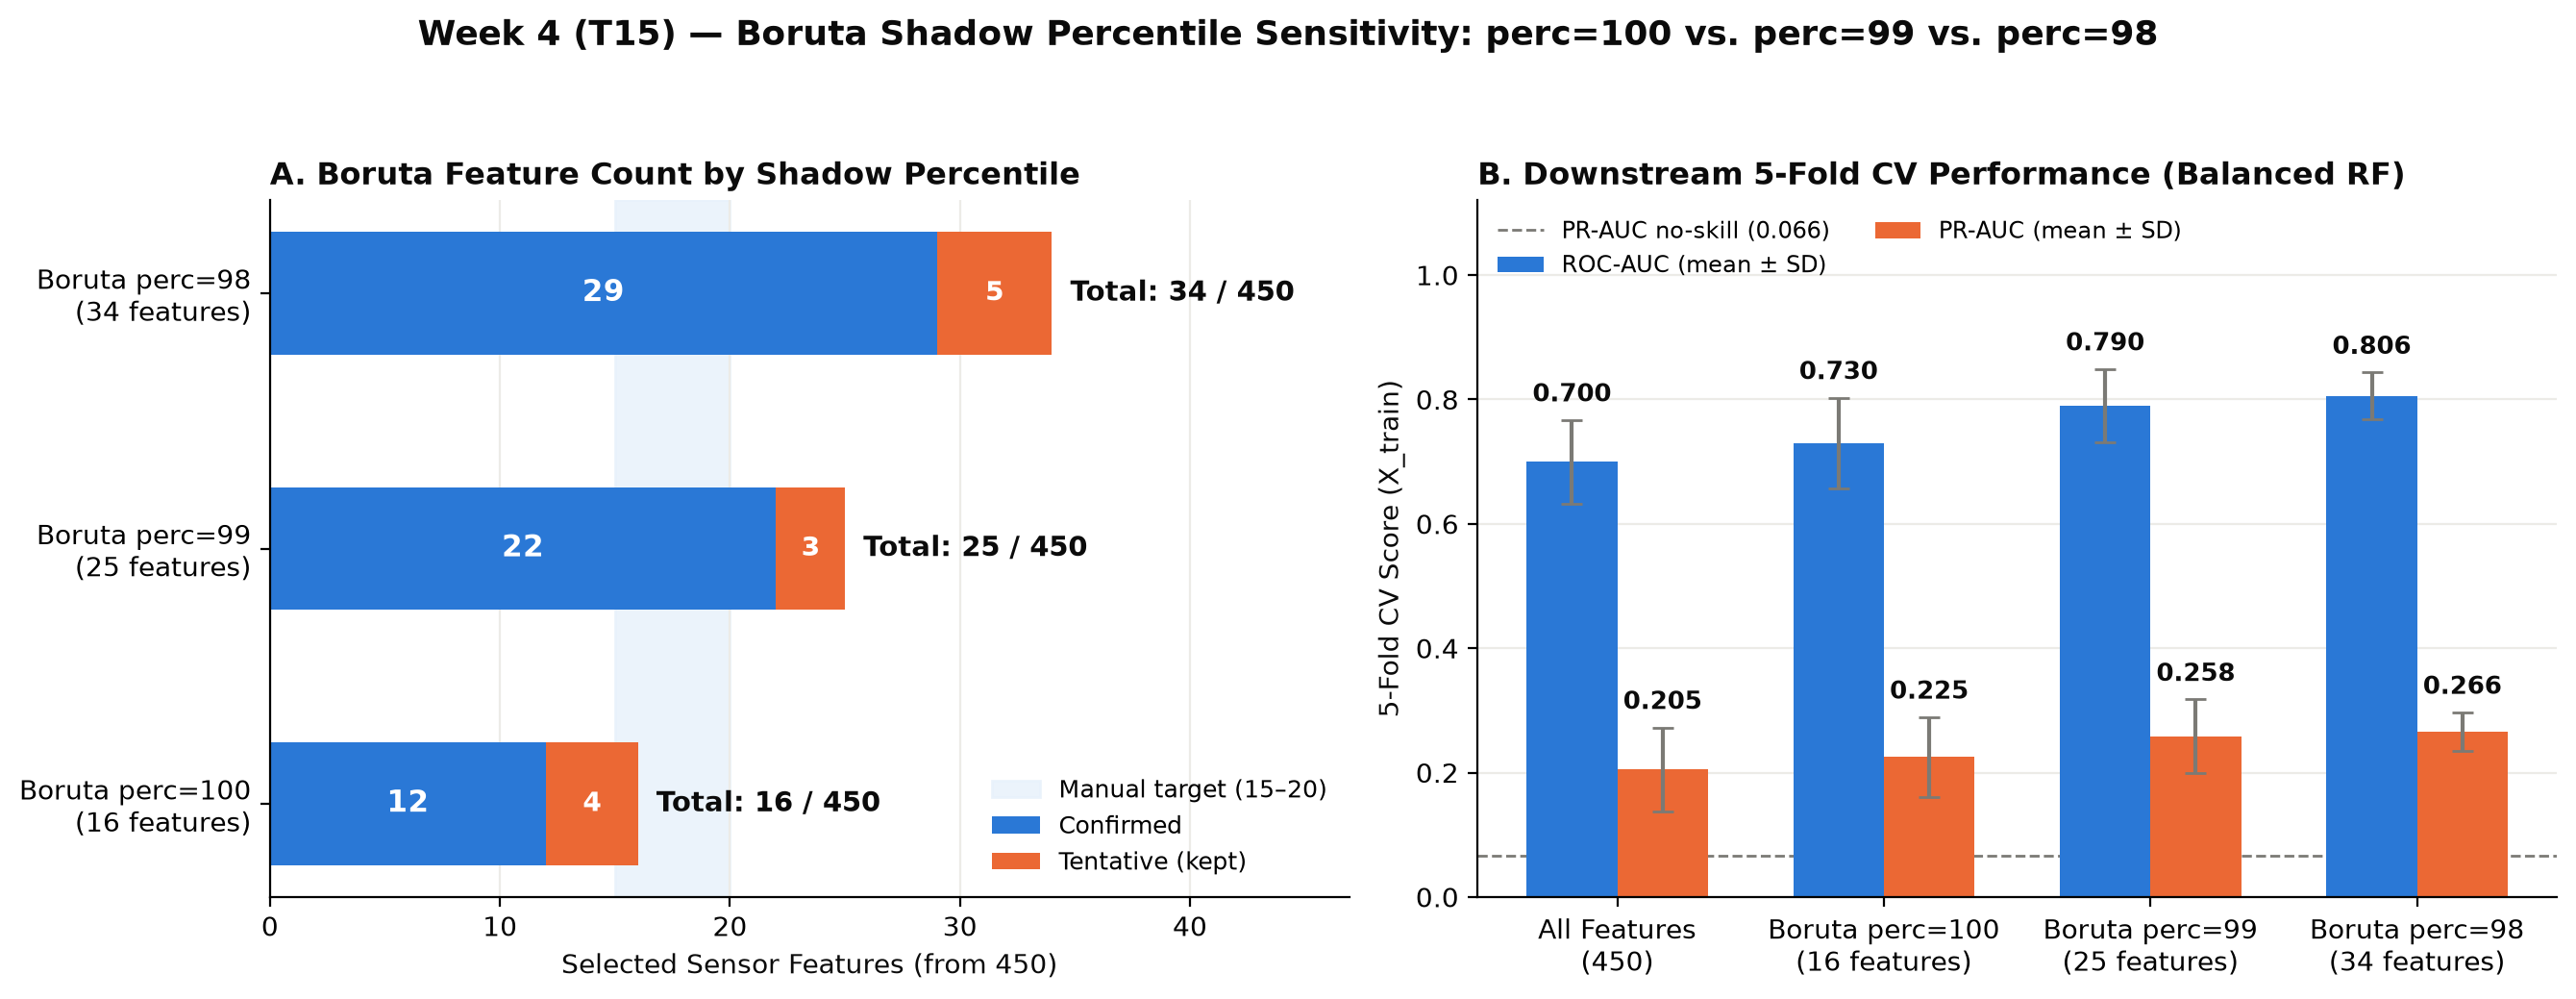

In [5]:
boruta_sip = pd.read_csv(W4_REPORTS / "t15_boruta_sip.csv")
display(boruta_sip)
print(f"Confirmed ({len(selected_meta['confirmed_features'])}): {selected_meta['confirmed_features']}")
print(f"Tentative ({len(selected_meta['tentative_features'])}): {selected_meta['tentative_features']}")
display(Image(filename=str(W4_REPORTS / "boruta_perc_comparison.png")))

---

## 5. Class Imbalance & Resampling Methods (Manual §9 / T16 — Week 4)

With only `83` defective wafers out of `1,253` (`6.62%`), a standard classifier minimises error by predicting almost every wafer as Pass (`0`).  
We compare four balancing strategies strictly inside each training fold (never touching validation or test rows):
- **Class weights (`balanced_subsample`)**: Up-weights minority errors without creating synthetic rows.
- **SMOTE**: Synthesises new defective wafers by interpolating between nearest minority neighbours (`83 → 1,170`).
- **ROSE-style (`RandomOverSampler(shrinkage=1.0)`)**: Python smoothed-bootstrap equivalent of R's ROSE (`83 → 1,170`).
- **ADASYN**: Generates more synthetic points around harder-to-learn minority samples (`83 → 1,156`).

,balancer,good_pass_0,defective_fail_1,total_rows,fail_pct
0,None (imbalanced),1170,83,1253,6.62
1,SMOTE,1170,1170,2340,50.00
2,ROSE-style,1170,1170,2340,50.00
3,ADASYN,1170,1156,2326,49.70


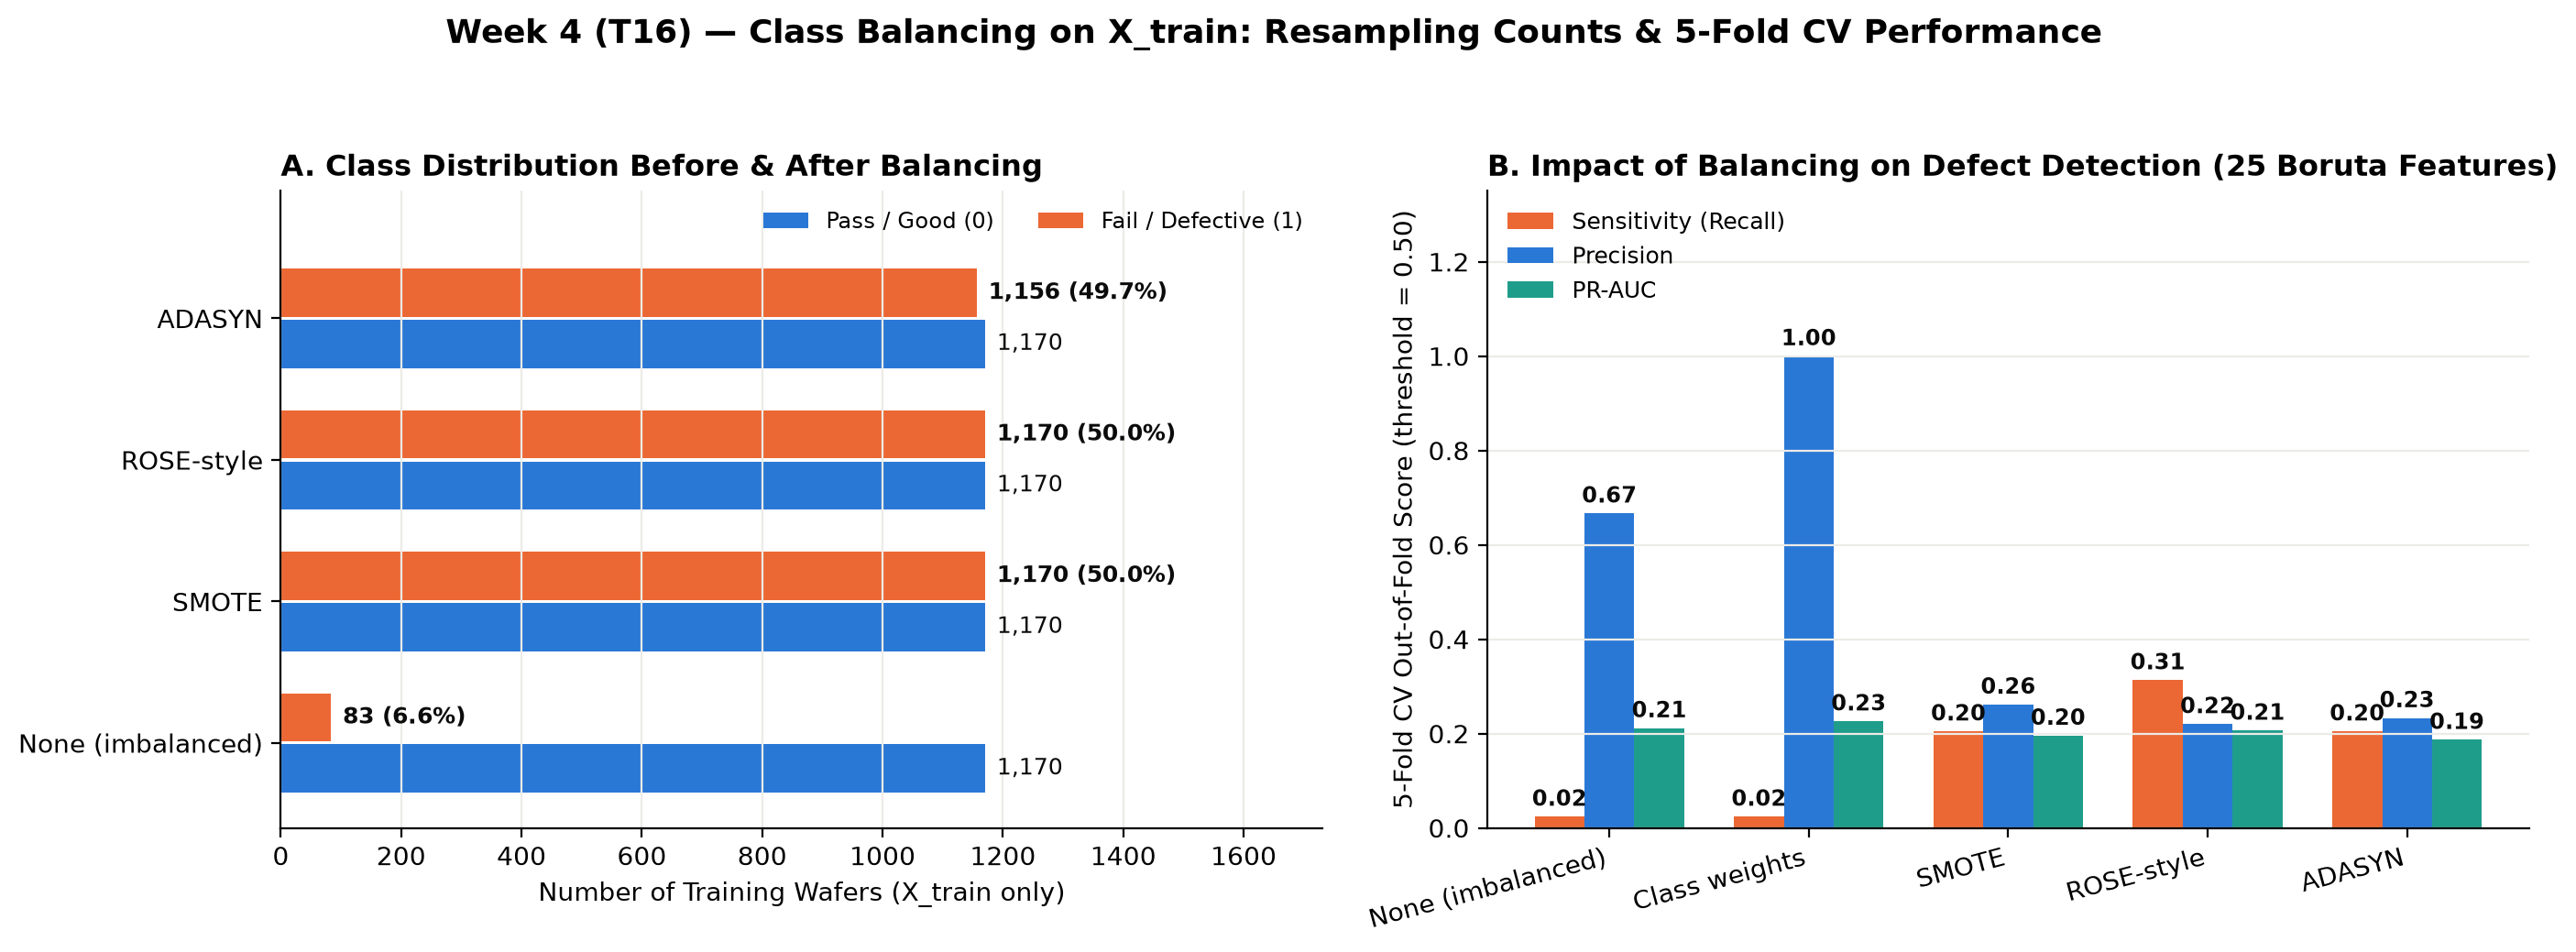

In [6]:
counts_df = pd.read_csv(W4_REPORTS / "t16_resampling_counts.csv")
display(counts_df)
display(Image(filename=str(W4_REPORTS / "t16_balancing_comparison.png")))

---

## 6. Initial Confusion Matrix, Type I/II Costs & Error Metrics (Manual §13 / T17 — Week 4)

- **Positive Class (`1`) = Defective Wafer**
  - **Type I Error (`FP`)**: Good wafer falsely flagged as defective → **Cost = `100`**.
  - **Type II Error (`FN`)**: Defective wafer missed and shipped → **Cost = `400`** (4× more expensive).
- **Total Asymmetric Cost**: $\text{Cost} = 100 \cdot \text{FP} + 400 \cdot \text{FN}$ (Always-pass baseline = $83 \times 400 = \mathbf{33,200}$).

,balancer,TP,FN,FP,TN,accuracy,sensitivity,specificity,precision,f1,f2,roc_auc,pr_auc,cost
0,Always-pass baseline,0,83,0,1170,0.934,0.000,1.000,0.000,0.000,0.000,0.500,0.066,33200
1,None (imbalanced),2,81,1,1169,0.935,0.024,0.999,0.667,0.047,0.030,0.754,0.212,32500
2,Class weights,2,81,0,1170,0.935,0.024,1.000,1.000,0.047,0.030,0.795,0.226,32400
3,SMOTE,17,66,48,1122,0.909,0.205,0.959,0.262,0.230,0.214,0.778,0.196,31200
4,ROSE-style,26,57,92,1078,0.881,0.313,0.921,0.220,0.259,0.289,0.739,0.206,32000
5,ADASYN,17,66,56,1114,0.903,0.205,0.952,0.233,0.218,0.210,0.771,0.187,32000


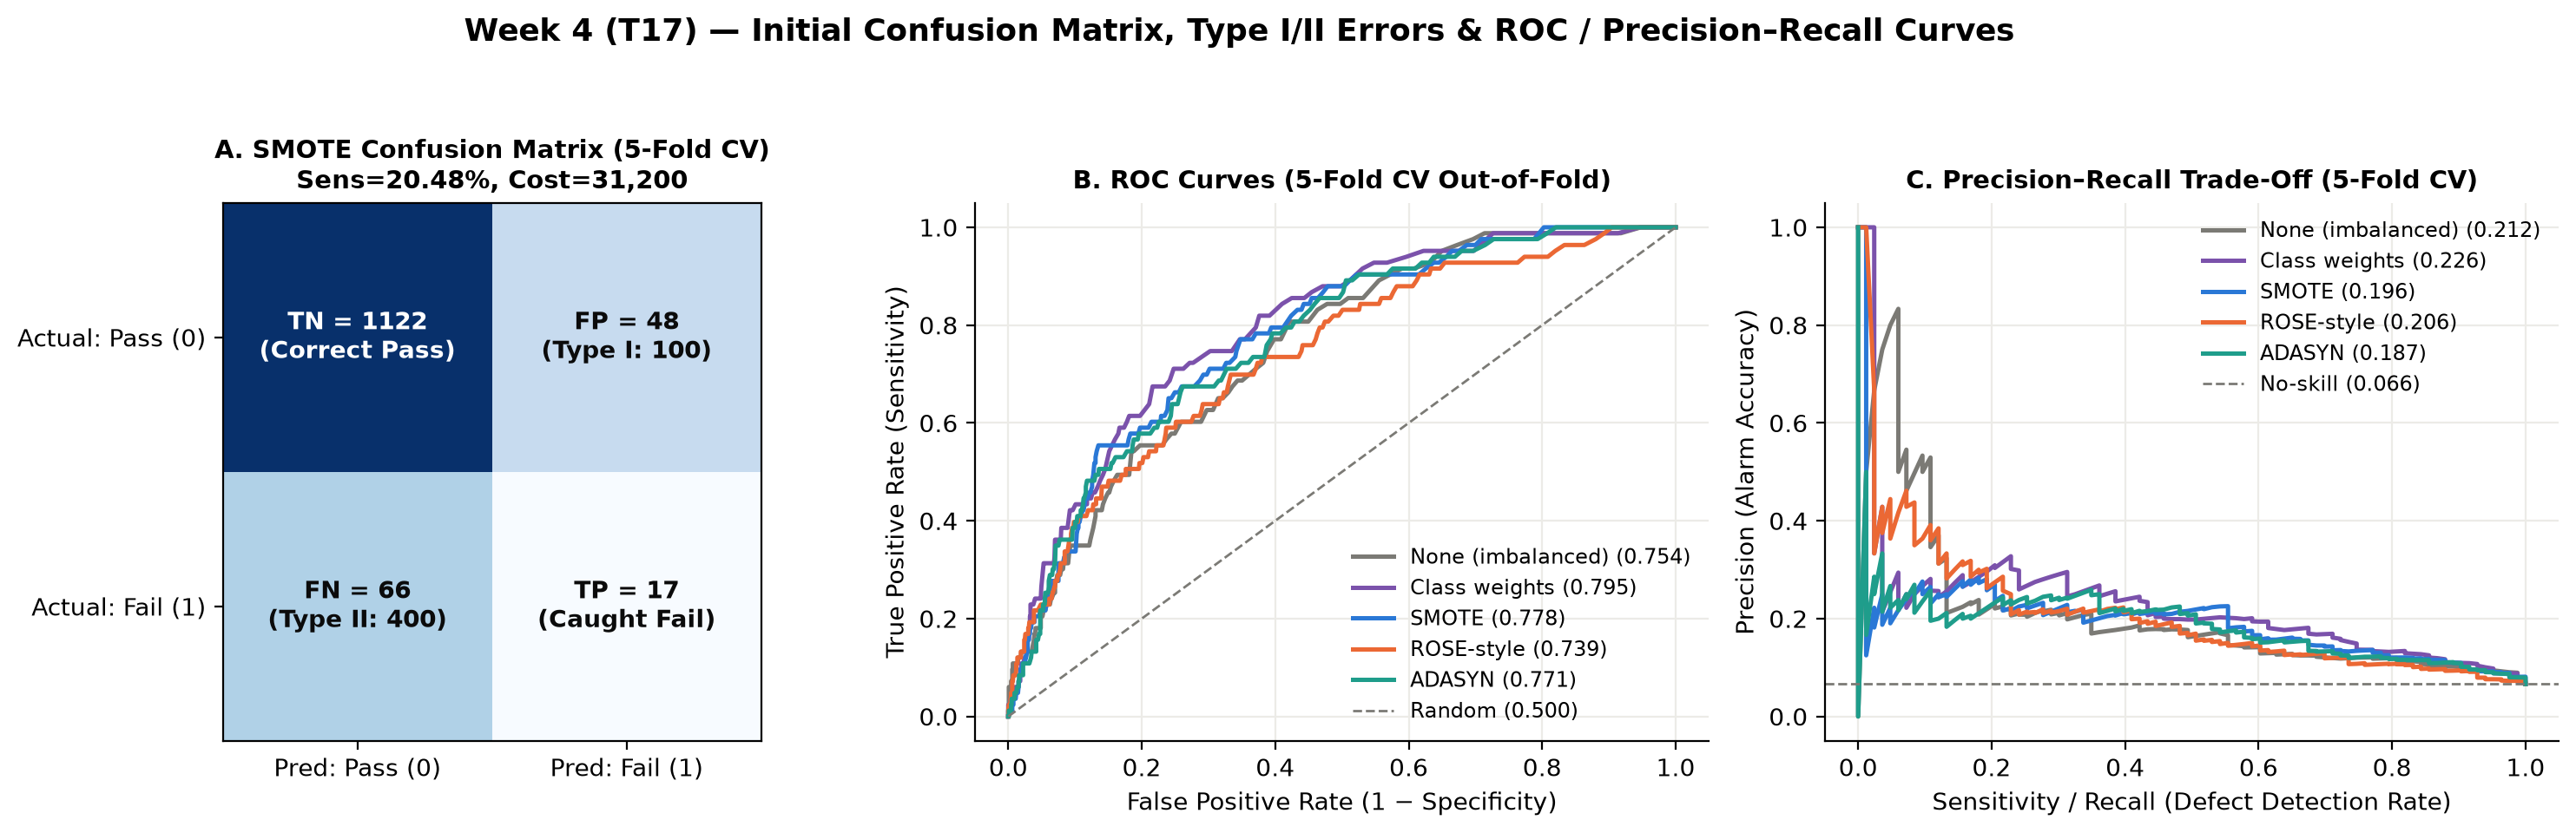

Options / approaches,Pro and con,Decision made,Consequence
nan,nan,nan,nan
nan,nan,nan,nan
nan,nan,nan,nan


In [7]:
metrics_df = pd.read_csv(W4_REPORTS / "t17_balancer_metrics_cv.csv")
cols = ["balancer", "TP", "FN", "FP", "TN", "accuracy", "sensitivity", "specificity", "precision", "f1", "f2", "roc_auc", "pr_auc", "cost"]
display(metrics_df[cols].round(3))
display(Image(filename=str(W4_REPORTS / "t17_confusion_and_curves.png")))

display(sip_table([
    {
        "options": "None / Class weights (threshold = 0.50)",
        "pros_cons": "+ Highest ROC-AUC (0.795) & PR-AUC (0.226) / - Catches only 2/83 defects (2.4% recall) at default 0.50",
        "decision": "Keep Class weights for Week 6 threshold tuning",
        "consequence": "Cost 32,400 at 0.50; strong candidate once threshold < 0.50",
    },
    {
        "options": "SMOTE (50/50 balanced fit)",
        "pros_cons": "+ Lowest cost at 0.50 (31,200, beats always-pass by 2,000); lifts recall 8.5x (20.5%) / - Synthetic overlap noise",
        "decision": "Chosen primary default",
        "consequence": "TP=17, FN=66, FP=48, TN=1,122; ROC-AUC 0.778",
    },
    {
        "options": "ROSE-style / ADASYN",
        "pros_cons": "+ ROSE-style hits highest Sensitivity (31.3%, 26/83 caught) & F2 (0.289) / - Higher false alarms (FP=92)",
        "decision": "Keep for Week 6 grid search",
        "consequence": "Cost 32,000 at 0.50",
    },
]))

---

## 7. Normality Audit & Visual Proof (Manual §8.1–8.2 — Week 5)

Before choosing whether to apply a normality transformation, we audit all `25` Boruta features with the **Shapiro-Wilk test** and compare **`No transform` vs. `Yeo-Johnson`** via 5-fold CV on both **Random Forest** (non-parametric) and **Logistic Regression** (linear):
- **`25 / 25`** Boruta sensors reject normality both raw and after Yeo-Johnson ($p < 0.05$).
- **`8 / 25`** sensors contain values $\le 0$, making **Box-Cox mathematically invalid**.
- **Empirical Proof:** Random Forest is invariant to Yeo-Johnson (`ROC-AUC 0.777 vs. 0.780`, with **lower cost without transform: `31,600` vs. `32,700`**), whereas Logistic Regression benefits from Yeo-Johnson (`Sensitivity 54.2% → 59.0%`, `Cost 43,100 → 42,700`). Therefore we **skip normality transforms for Random Forest** and keep Yeo-Johnson as a switchable option for linear models in Week 6.

,model,model_family,normality,roc_auc,pr_auc,sensitivity,cost
0,Random Forest (SMOTE),random_forest,No transform,0.7767,0.2010,0.2048,31600
1,Random Forest (SMOTE),random_forest,Yeo-Johnson,0.7802,0.2059,0.1807,32700
2,Logistic Regression (SMOTE),logreg,No transform,0.7433,0.1828,0.5422,43100
3,Logistic Regression (SMOTE),logreg,Yeo-Johnson,0.7477,0.1890,0.5904,42700


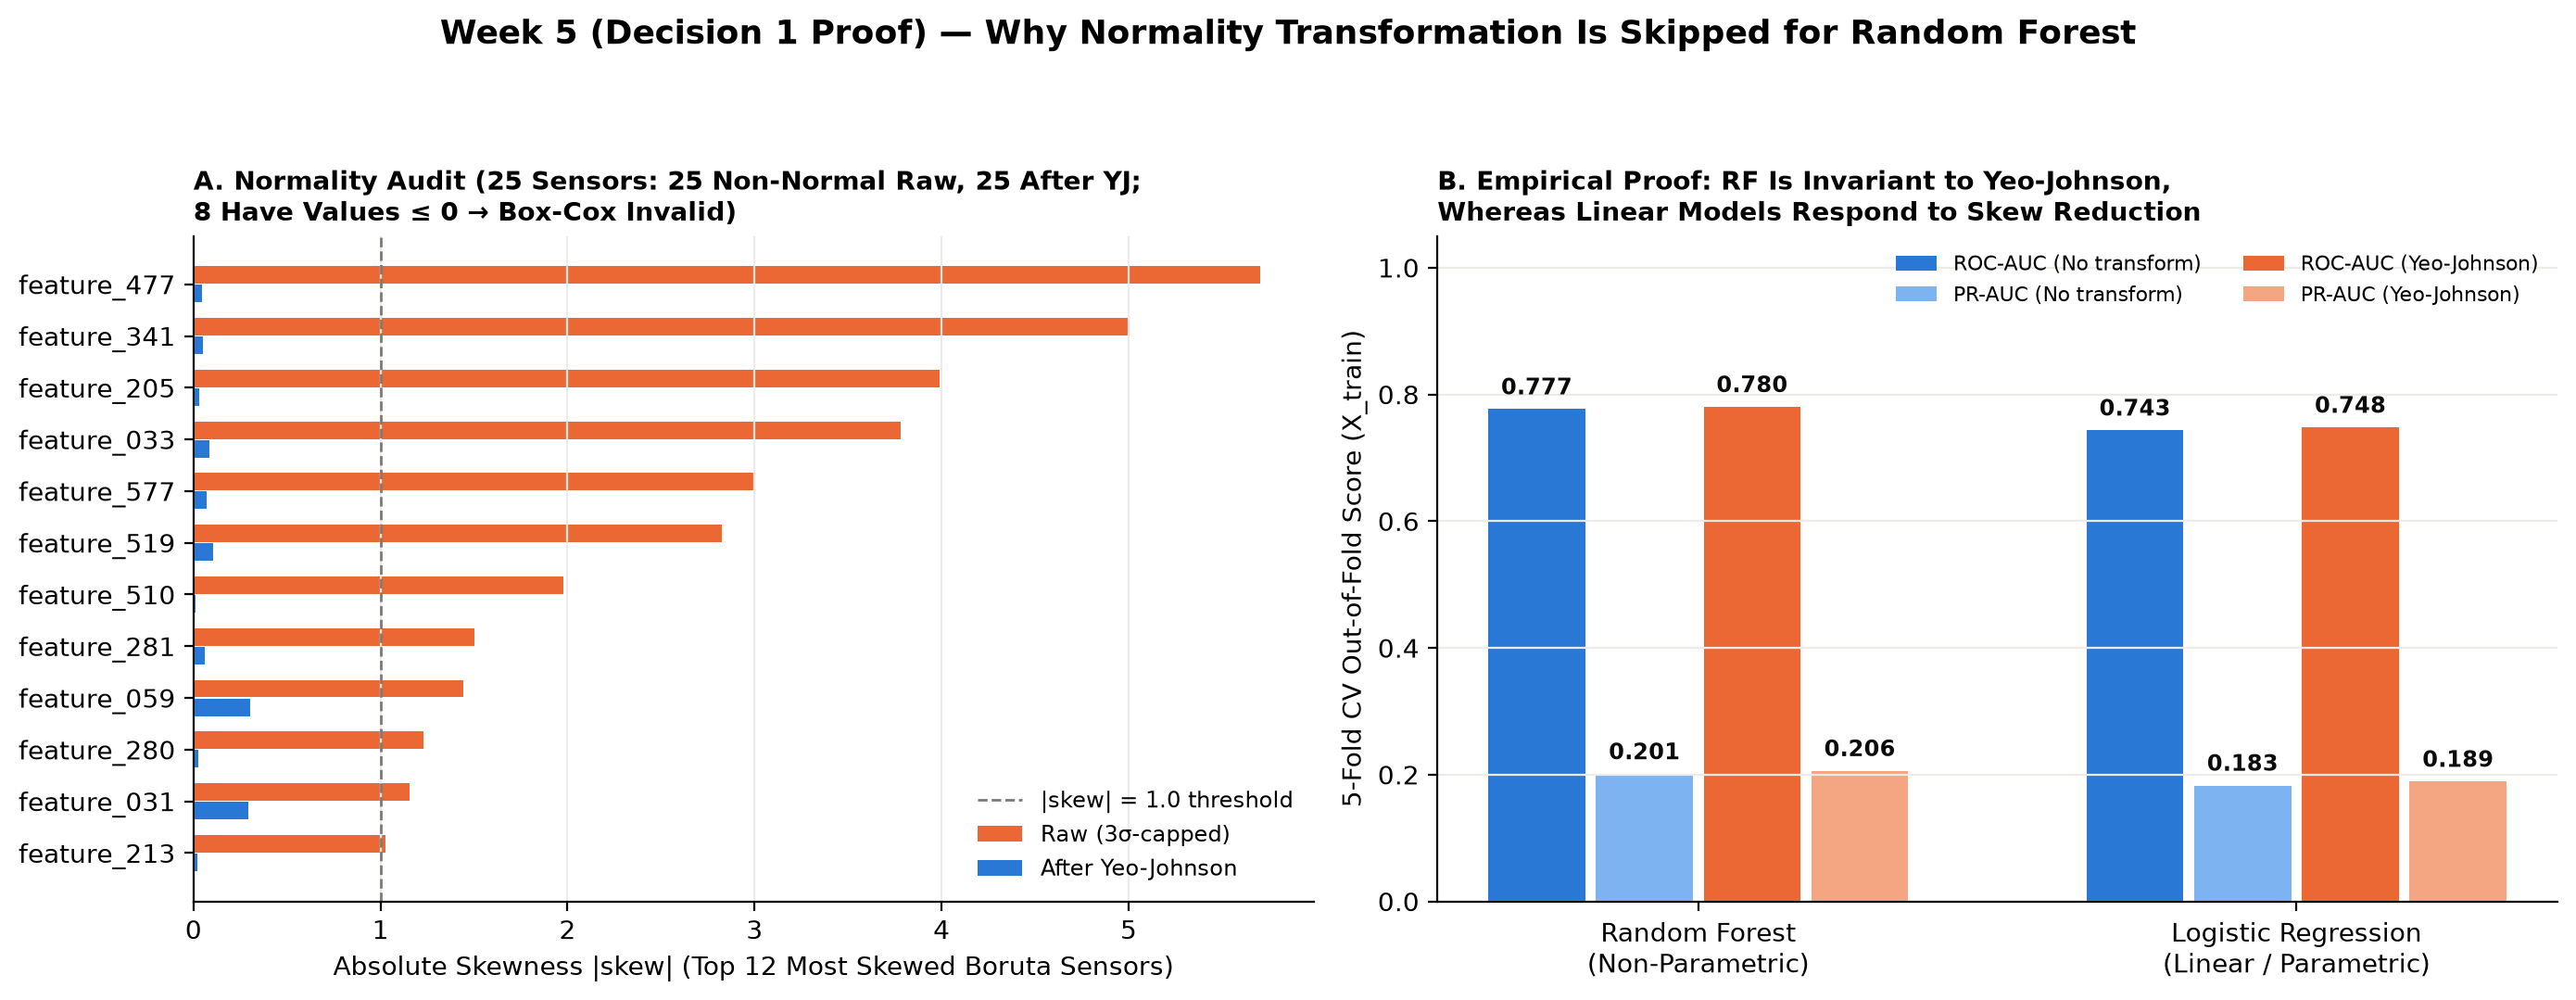

In [8]:
cv_proof = pd.read_csv(W5_REPORTS / "w5_normality_cv_proof.csv")
display(cv_proof.round(4))
display(Image(filename=str(W5_REPORTS / "w5_normality_proof.png")))

---

## 8. Min-Max Scaling (`[0, 1]`), Leakage-Free `imblearn` Pipeline & Process Map (Manual §8.3–8.5 & §10 — Week 5)

Using `imblearn.pipeline.Pipeline` in §17.1 order (`OutlierTreatment (3σ)` → `FrameKNNImputer (k=5)` → `Selector (25 Boruta)` → `FrameMinMaxScaler [0, 1]` → `SMOTE` → `RandomForest`) guarantees:
1. Every preprocessing parameter is fitted **strictly on each training fold**.
2. `FrameMinMaxScaler` scales the `25` selected features to exact `[0.0, 1.0]` on train without altering distribution shapes, ensuring SMOTE's Euclidean distances weight every sensor equally.
3. `SMOTE` runs **only during `.fit()`** and is automatically bypassed during `.predict()` / `.predict_proba()`.

,Pipeline Check (§10.5),Verified Value
0,fold0_train_rows,1002
1,fold0_valid_rows,251
2,shared_indices,0
3,features_in,450
4,features_after_selector,25
5,minmax_train_min,0.0
6,minmax_train_max,1.0
7,rows_after_smote_train_only,1872
8,smote_train_fail_count,936
9,valid_predictions_count,251


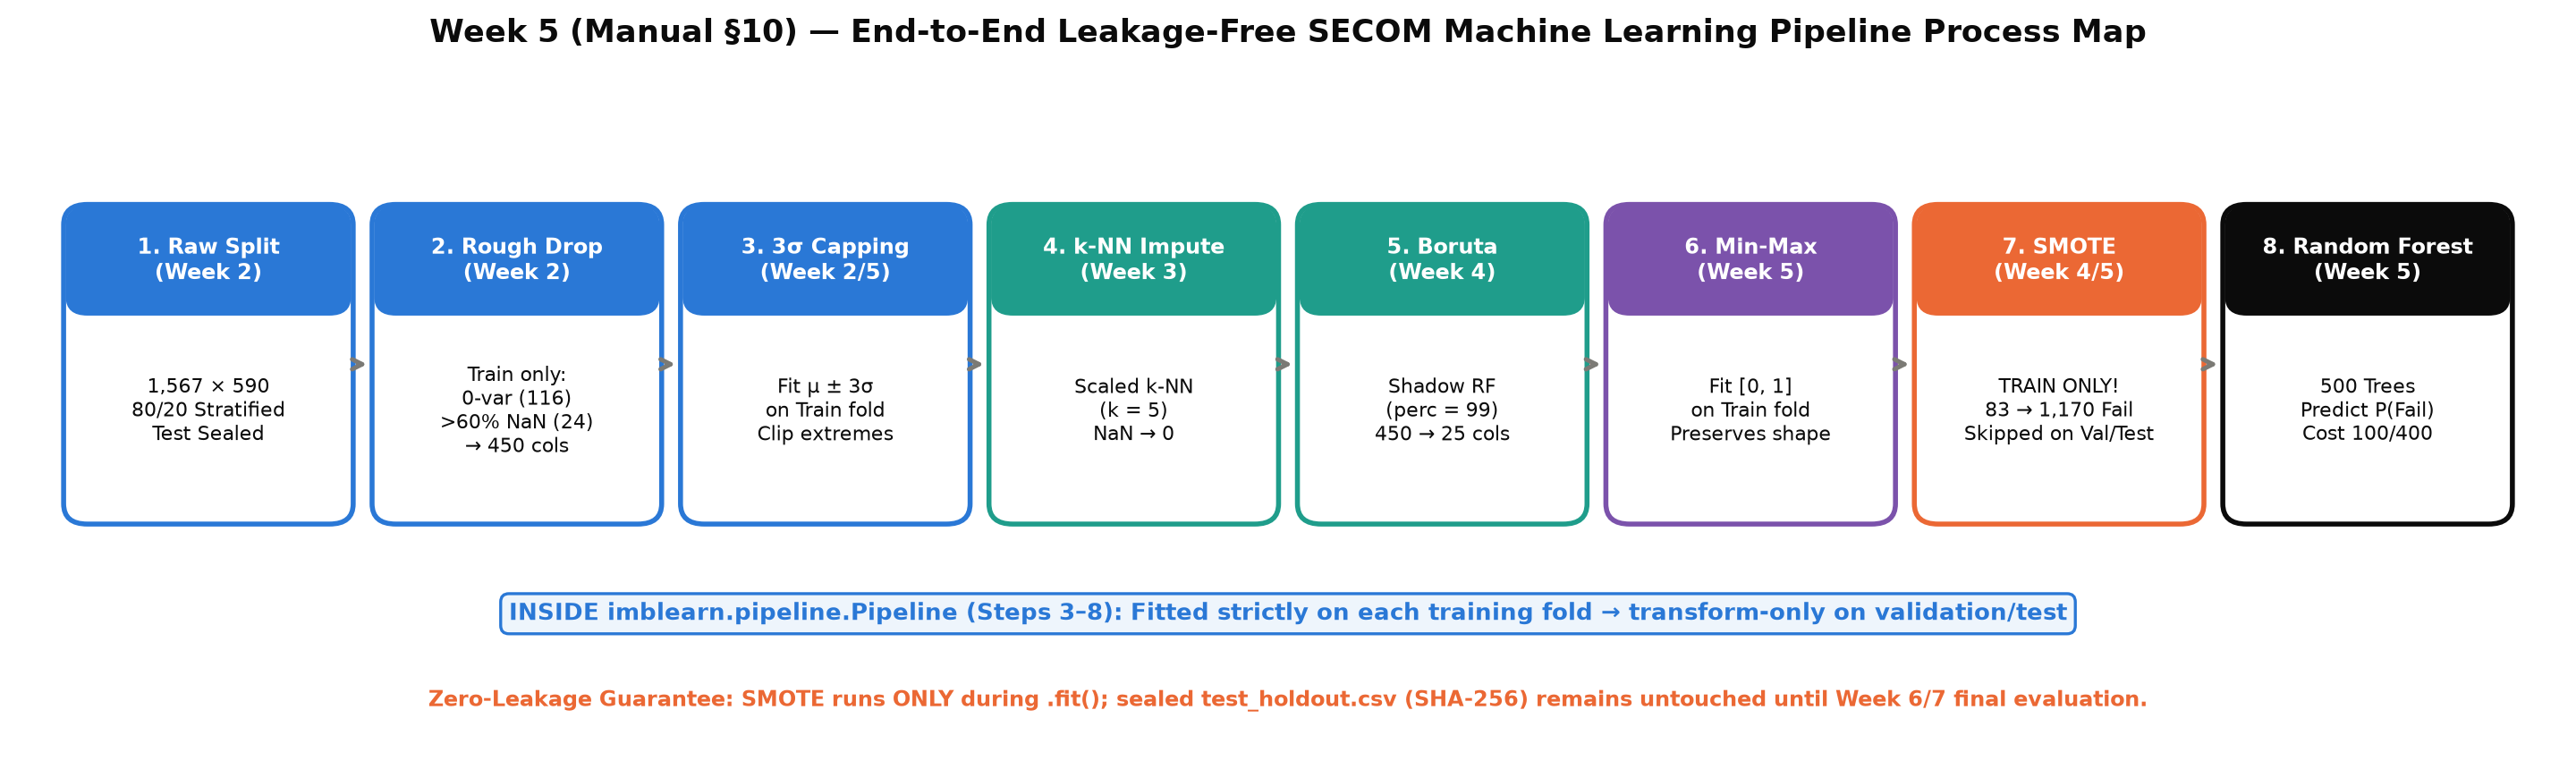

In [9]:
checks = json.loads((W5_REPORTS / "w5_pipeline_checks.json").read_text(encoding="utf-8"))
display(pd.DataFrame(list(checks.items()), columns=["Pipeline Check (§10.5)", "Verified Value"]))
display(Image(filename=str(W5_REPORTS / "w5_pipeline_process_map.png")))

---

## 9. Training Error vs. Unseen Validation Error & Model Complexity (Week 5)

To demonstrate the fundamental relationship $\text{Training Error} < \text{Unseen Error}$ **without breaking the SHA-256 test-set seal before Week 6 tuning**, we sweep Random Forest `max_depth` from `2` to `None` (unlimited) across Stratified 5-Fold CV on `X_train`:

,max_depth,train_error,val_error,gap_error,train_roc_auc,val_roc_auc,val_sensitivity
0,2,0.2308,0.2578,0.0270,0.8575,0.7213,0.4794
1,3,0.1867,0.2299,0.0431,0.9030,0.7329,0.4816
2,5,0.1145,0.1732,0.0587,0.9701,0.7529,0.4324
3,8,0.0547,0.1365,0.0818,0.9979,0.7681,0.3846
4,12,0.0190,0.1053,0.0864,0.9999,0.7758,0.2772
5,20,0.0004,0.0974,0.0970,1.0000,0.7797,0.1926
6,None (unlimited),0.0000,0.0966,0.0966,1.0000,0.7794,0.1926


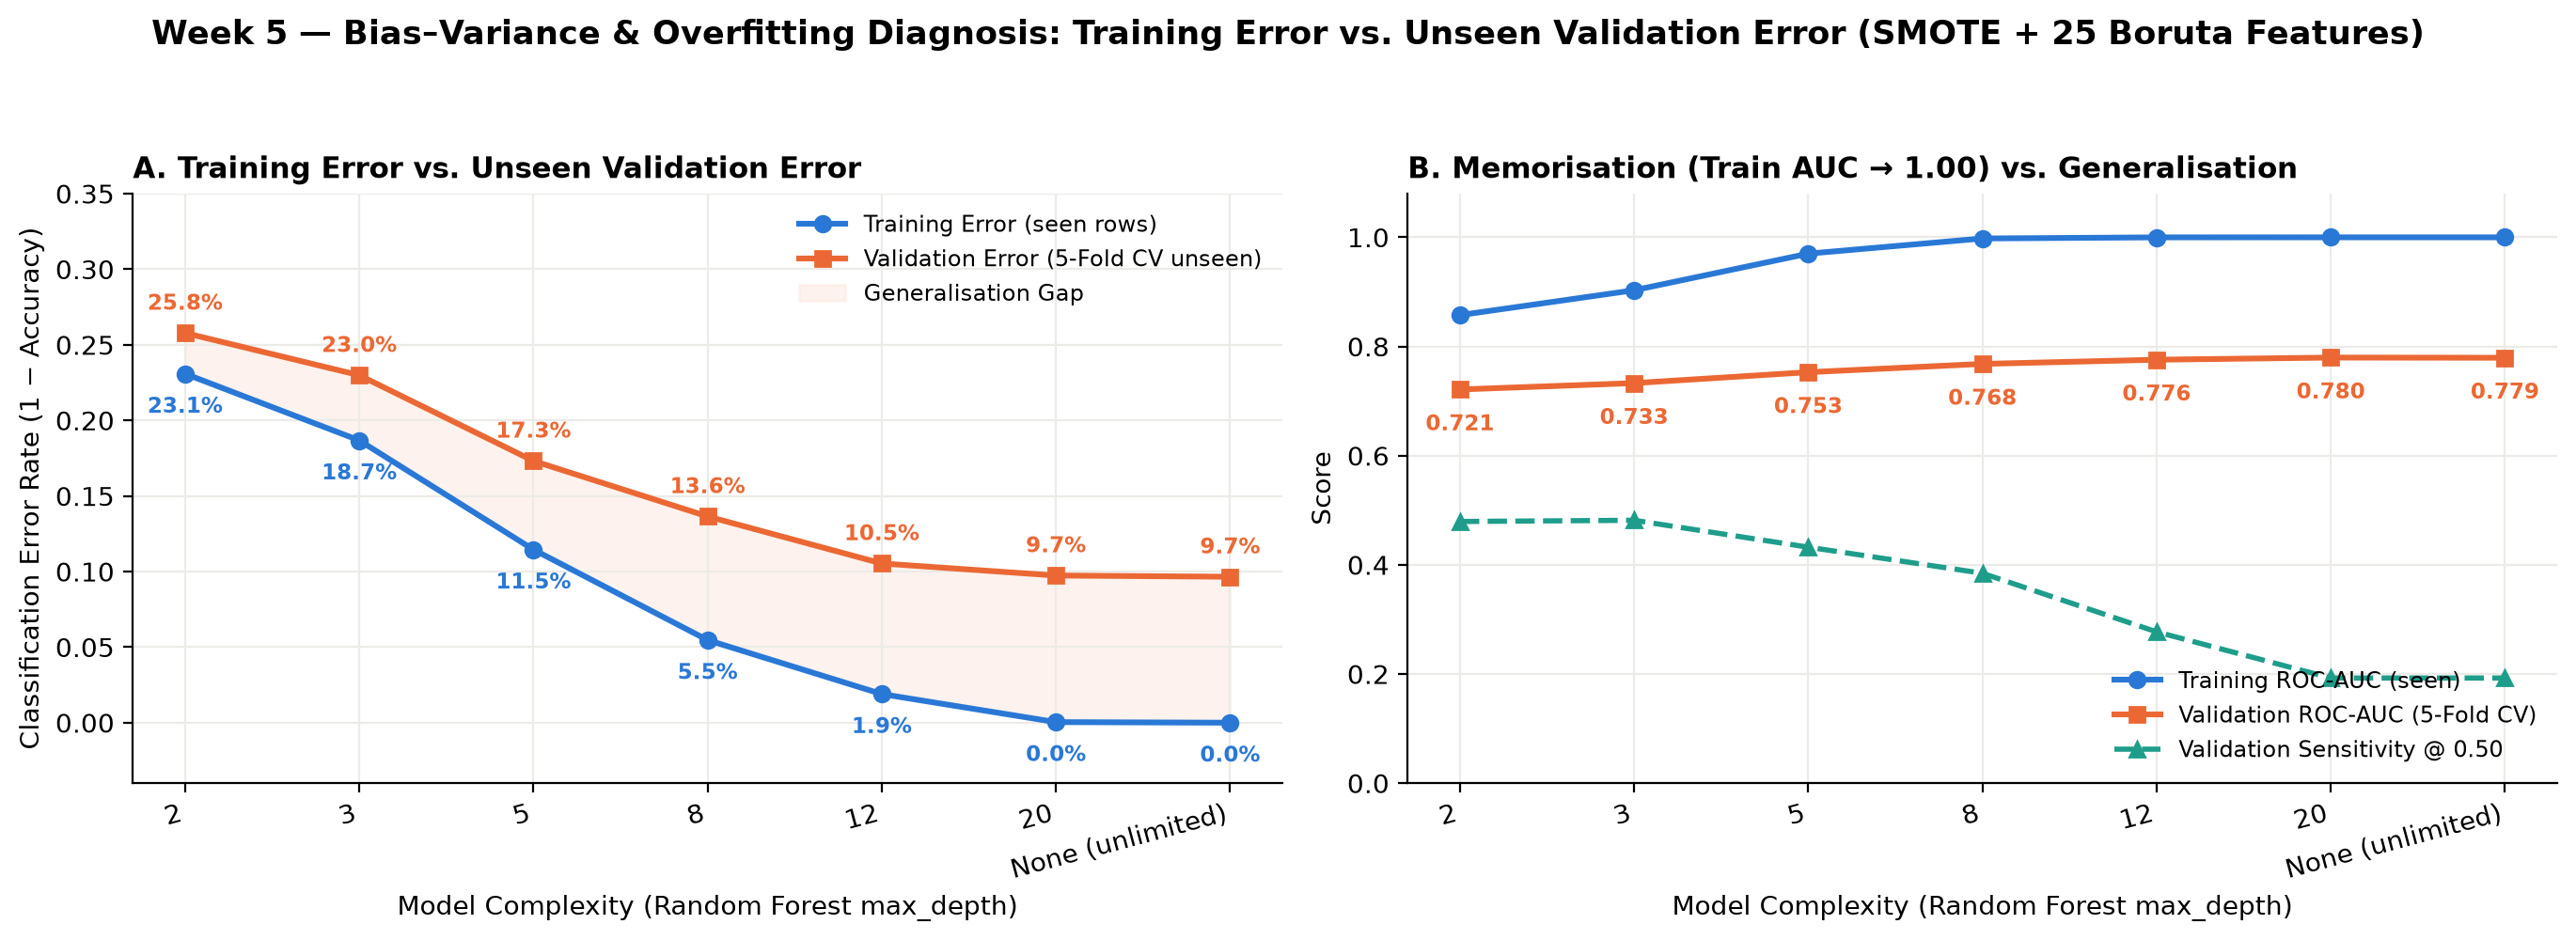

In [10]:
curve_df = pd.read_csv(W5_REPORTS / "w5_complexity_curve.csv")
display(curve_df.round(4))
display(Image(filename=str(W5_REPORTS / "w5_train_vs_val_complexity.png")))

**Key Finding:** At `max_depth = None`, Training Error hits **`0.0%`** (`Train ROC-AUC = 1.000` — complete memorisation of `X_train`) while unseen Validation Error stays at **`9.7%`** and Validation Sensitivity drops to `19.3%`. By contrast, shallow regularised trees (`max_depth = 3–5`) shrink the generalisation gap to `4.3–5.9%` and lift Validation Sensitivity to **`43–48%`**!

---

## 10. Summary & Next Steps (Entering Week 6)
- **Completed (Weeks 1–5):** EDA & Data Health → Sealed Stratified 80/20 Split → Rough Reduction (`590 → 450`) → `3σ` Capping → Scaled `k-NN` (`k=5`, `0` `NaN`s) → Boruta (`perc=99`, `450 → 25`) → Class Balancing (`SMOTE` default; `ROSE-style`, `Class weights`, `ADASYN` retained) → Normality Proof & Min-Max `[0, 1]` → Leakage-Free `imblearn` Pipeline & Complexity Diagnosis.
- **Test Set Seal:** `data/processed/test_holdout.csv` remains **100% untouched**.
- **Next (Week 6 in `src/secom_analysis/week6/`):** Multi-model comparison (`Dummy`, `LogisticRegression`, `RandomForest`, `HistGradientBoosting`), systematic Grid Search (`OutlierTreatment` × `k-NN k` × `Balancer` × `RF max_depth/min_samples_leaf`), cost-optimal probability threshold selection (`100·FP + 400·FN`), and finally the **one-time evaluation on the sealed test set**.